# pyGIMLi(empymod)

v1: trying to implement pyDGSA functionality to do systematic study of inversion parameters

DGSA STUDY NR. 1

Survey to test with:
- 1 source of length 20 at 200 m distance
- 4 frequencies: [10, 1000, 10000, 30000]
- 40 receivers x 4 frequencies => 160 data points
- cells of 2.5 m for 300 m depth => 120 DOF
- baseline resistivity of 35 Ohmm

Criteria:
- resistance contrast [13, 25]
- anomaly thickness [10, 80]
- anomaly depth [150, 250]
- noise level [1%, 20%]

Amount of simulations = 2^4 -> 16 simulations

Note: real amount of simulations is 16 x 5 due to testing for different noise manifestations

Metrics:
- misfit (save the remanent misfit)
- chi2 value (save the initial and final chi2 value)
- amount of iterations (save the amount of iterations)
- detectability (average all the models, divide the final model average by the starting model average, compare this with the same for the true model)
- accuracy of anomaly resistivity absolute (find the final resistivity of the anomaly averaged over all the anomaly cells)
- accuracy of anomaly resistivity relative (divide the above by the true model anomaly resistivity)
- accuracy of baseline resistivity (same as for anomaly)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import pygimli
import empymod
import pandas as pd

In [5]:
#We want to use different sets of noise in order to arrive at the final metrics

real_rngs = []
imag_rngs = []

for i in np.arange(5):
    #Random number regenerator used to set the noise
    real_rngs.append(np.random.default_rng(seed=i))
    imag_rngs.append(np.random.default_rng(seed=i*2+1))

## Create survey, model, and data

In [68]:
# Fixed parameters

# Survey: Offsets and Frequencies
rec_offsets = np.arange(0, 300, 7.5)
frequencies = [10, 1000, 10000, 30000]

#Baeline resistivity definition
base_res = 35 #Ohmm
depths = np.arange(0, 300, 10)

# Collect input parameters
inp = {
    'src': [-200, -180, 0, 0, 0, 0],
    'rec': [rec_offsets*0, rec_offsets*0, rec_offsets, 0, 90],
    'depth': depths,
    'freqtime': frequencies,
    'verb': 1,
}

noise_floor = 1e-15
mean_noise = 0.0

In [69]:
# DGSA/non-fixed parameters

res_anoms = [13, 25]
thick_anoms = [10, 80]
depth_anoms = [150, 210]
noise_levels = [0.01, 0.2]

In [72]:
#Construct data for all the simulations

params_list = []
dobs_list = []
d0_list = []
std_dev_list = []
mtrue_list = []

for anom_res in res_anoms:
    for thick in thick_anoms:
        for depth in depth_anoms:
            for relative_error in noise_levels:
                for i in np.arange(5):
                    rel_noise = relative_error

                    # Model depths and resistivities
                    mtrue = np.r_[2e14, [base_res]*int(depth/10), [anom_res]*int(thick/10), [base_res]*int(30-(depth+thick)/10)]
                    m0 = np.r_[2e14, [base_res]*30]

                    # Create observed data and background == start model data
                    dobs = empymod.bipole(res=mtrue, **inp)
                    d0 = empymod.bipole(res=m0, **inp)

                    # Exclude data below half the noise_floor
                    cut_data = abs(dobs) < (noise_floor / 2)
                    dobs[cut_data] = np.nan + 1j*np.nan
                    d0[cut_data] = np.nan + 1j*np.nan

                    # Add random white noise to dobs
                    std_dev_real = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.real)**2)
                    std_dev_imag = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.imag)**2)
                    noise_real = real_rngs[i].normal(loc=0, scale=std_dev_real, size = dobs.shape)
                    noise_imag = imag_rngs[i].normal(loc=0, scale=std_dev_imag, size = dobs.shape)
                    std_dev = std_dev_real + 1j*std_dev_imag
                    noise = noise_real + 1j*noise_imag
                    dobs += noise

                    params_list.append([anom_res, thick, depth, relative_error, i])
                    dobs_list.append(dobs)
                    d0_list.append(d0)
                    std_dev_list.append(std_dev)
                    mtrue_list.append(mtrue)


In [9]:
#pd.DataFrame(np.array(mtrue_list[::5])[:,14:])

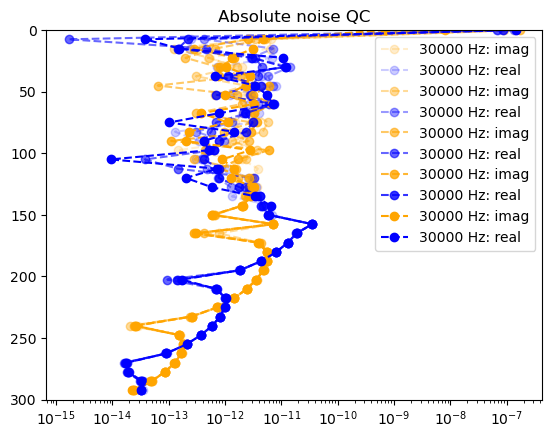

In [10]:
#QC the noise

for i in np.arange(5):

    j = 3 #change this to change the frequency

    noise = dobs_list[i][j] - d0_list[i][j]

    #print("Shape of noise: ", np.shape(noise))
    #print("Mean noise: ", np.mean(np.abs(noise)))
    #print("Minimum noise: ", np.min(noise))
    #print("Maximum noise: ", np.max(noise))

    plt.title('Absolute noise QC')
    plt.plot(abs(np.imag(noise)), rec_offsets, 'o--', c=('orange', (i+1)*0.2), label=str(frequencies[j])+' Hz: imag')
    plt.plot(abs(np.real(noise)), rec_offsets, 'o--', c=('blue', (i+1)*0.2), label=str(frequencies[j])+' Hz: real')
    plt.ylim([300, 0])
    #plt.xlim([1e-10, 4e-8])
    plt.xscale('log')
    plt.legend()

In [11]:
# QC models produced
fig, axs = plt.subplots(4, int(parameters.shape[0]/4+0.5), figsize=(10, 10), tight_layout=True)

p_depth = np.r_[-10, np.repeat(depths, 2), 3000]
p_m0 = np.repeat(m0, 2)
print(parameters.shape[0])
for i in np.arange(parameters.shape[0]):
    p_mtrue = np.repeat(mtrue_list[::5][i], 2)

    ax1=axs[int((i-i%4)/4), i%4]

    # Plot Resistivities
    ax1.set_title('Simulation '+str(i))
    ax1.plot(p_mtrue, p_depth, 'C3', label="True Model")
    ax1.plot(p_m0, p_depth, 'k', label="Start Model")
    #ax1.set_xscale('log')
    ax1.set_xlim([0, 70])
    ax1.set_ylim([depths[-1]+50, depths[0]-10])
    ax1.set_ylabel('Depth (m)')
    ax1.set_xlabel(r'Resistivity $\rho_h\ (\Omega\,\rm{m})$')

NameError: name 'parameters' is not defined

## QC model and data

C:\Users\suzannevannoor\AppData\Local\Temp\ipykernel_15924\2818458584.py:39: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_xscale('log')
c:\Users\suzannevannoor\AppData\Local\anaconda3\envs\pg\Lib\site-packages\IPython\core\events.py:100: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  func(*args, **kwargs)
c:\Users\suzannevannoor\AppData\Local\anaconda3\envs\pg\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.canvas.print_figure(bytes_io, **kw)


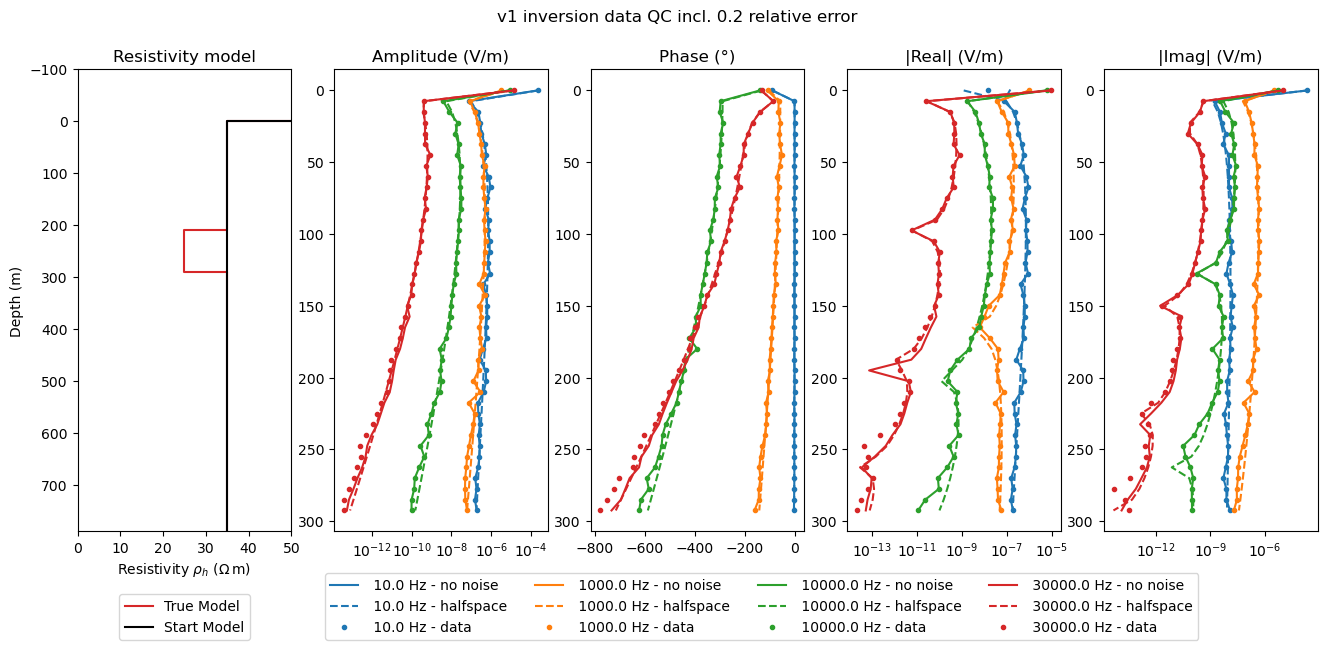

In [12]:
# Plot it
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, figsize=(16, 6), tight_layout=True)
axes = [ax1, ax2, ax3, ax4, ax5]

p_mtrue = np.repeat(mtrue, 2)
p_m0 = np.repeat(m0, 2)
p_depth = np.r_[-100, np.repeat(depths, 2), 3000]

# Plot Resistivities
ax1.set_title('Resistivity model')
ax1.plot(p_mtrue, p_depth, 'C3', label="True Model")
ax1.plot(p_m0, p_depth, 'k', label="Start Model")
#ax1.set_xscale('log')
ax1.set_xlim([0, 50])
ax1.set_ylim([depths[-1]+500, depths[0]-100])
ax1.set_ylabel('Depth (m)')
ax1.set_xlabel(r'Resistivity $\rho_h\ (\Omega\,\rm{m})$')


#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [dobs.amp(), dobs.pha(deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [(dobs-noise).amp(), (dobs-noise).pha(deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data00 = [d0.amp(), d0.pha(deg=True), abs(d0.real), abs(d0.imag)]
fig.suptitle("v1 inversion data QC incl. "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j+1]
    ax.set_title(labels[j])
    for i, f in enumerate(frequencies):
        if len(frequencies) == 1:
            ax.plot(data0[j][:], rec_offsets, 'C'+str(i)+'-', label = f"{f: 2.1f} Hz - no noise")
            ax.plot(data00[j][:], rec_offsets, 'C'+str(i)+'--', label = f"{f: 2.1f} Hz - halfspace")
            ax.plot(data_obs[j][:], rec_offsets, 'C'+str(i)+'.', label=f"{f: 2.1f} Hz - data")
        else:
            ax.plot(data0[j][i,:], rec_offsets, 'C'+str(i)+'-', label = f"{f: 2.1f} Hz - no noise")
            ax.plot(data00[j][i,:], rec_offsets, 'C'+str(i)+'--', label = f"{f: 2.1f} Hz - halfspace")
            ax.plot(data_obs[j][i,:], rec_offsets, 'C'+str(i)+'.', label=f"{f: 2.1f} Hz - data")
    ax.invert_yaxis()
    ax.set_xscale('log')
    #ax.legend(loc='upper left')
    #ax.set_xlim([-1e-7, 1e-7])

ax1.legend(loc='lower center', bbox_to_anchor = (0.5,-0.25))
ax2.legend(loc = 'lower center', bbox_to_anchor = (2,-0.25), ncols = 4)

ax3.set_xscale('linear')

#It can be seen that the imaginary noise is very high compared to the signal difference

## Forward Kernel and modified Inversion class
=> The following cell should go into `empymod.inv.pygimli`

In [13]:
class Kernel(pygimli.Modelling):
    
    def __init__(self, input_map, output_map, routine=empymod.bipole):
        """Initialize the model."""
        super().__init__()

        # Store inputs
        self.input_map = input_map
        self.output_map = output_map
        self.routine = routine
        
    def response(self, x):
        """Forward response.""" 
        #print('problem 0')   

        # Compute responses
        em = self.routine(**self.input_map(x))
        
        # Ravel output, taking care of complex values
        em = self.output_map(em)
        #em = np.r_[em.ravel().real]#, em.ravel().imag if np.iscomplexobj(em) else []]

        # Return required data
        return em if not hasattr(self, 'indices') else em[self.indices]
    
    def createStartModel(self, dataVals=None):
        """Overwrite default method with an Error.""" 
        raise NotImplementedError("Start Model must be provided.")

class Inversion(pygimli.Inversion):
    
    def run(self, dataVals, errorVals=None, **kwargs):

        # Store the mesh (pseudo)
        if "startModel" in kwargs:
            n_model = len(np.atleast_1d(kwargs["startModel"]))
        else:
            n_model = len(self.startModel)
        self.fop.mesh1d = pygimli.meshtools.createMesh1D(n_model)
        self.fop.setMesh(self.fop.mesh1d)

        # Error: Same as in original function, but taking care of complex data
        if errorVals is None:  # use absoluteError and/or relativeError instead
            absErr = kwargs.pop("absoluteError", 0)
            relErr = kwargs.pop("relativeError",
                                0.01 if np.allclose(absErr, 0) else 0)
            errorVals = abs(absErr / np.asarray(abs(dataVals))) + relErr

        if isinstance(errorVals, (float, int)):
            errorVals = np.ones_like(dataVals.real) * errorVals
        
        # Ravel data and decompose complex data
        d_size = dataVals.size
        d_shape = dataVals.shape
        is_complex = False
        if np.iscomplexobj(dataVals):
            is_complex = True
            d_size *= 2
        dataVals = np.r_[dataVals.ravel().real, dataVals.ravel().imag if is_complex else []]
        errorVals = np.r_[errorVals.ravel(), errorVals.ravel() if is_complex else []]

        # Limit to finite values
        if np.any(~np.isfinite(dataVals)):
            self.fop.indices = np.isfinite(dataVals)
            dataVals = dataVals[self.fop.indices]
            errorVals = errorVals[self.fop.indices]

        # Run the inversion
        model = super().run(dataVals=dataVals, errorVals=errorVals, **kwargs)

        # Reshape data           
        if hasattr(self.fop, 'indices'):
            out = np.ones(d_size)*np.nan
            out[self.fop.indices] = np.array(self.response)
        else:
            out = np.array(self.response)
        if is_complex:
            out = out[:d_size//2] + 1j*out[d_size//2:]               
        response = empymod.EMArray(np.reshape(out, d_shape))

        # Return mapped parameters and response
        return self.fop.input_map(model), response
    
    

## Inversion

The objective function is calculated like:

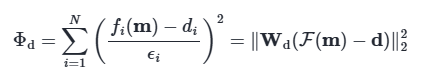

with f_i(m) the modelled data (forward response at the data point), d_i the data, eps_i the error, N the amount of data points. An expression in terms of W_d is derived with W_d being a data weighting matrix containing the inverse data errors and F(m) the forward model response vector.

Once the objective function is determined, we determine the gradient. This is done using Gauss-Newtonian method in our case, which works by solving the following formula using a least-squares solver:

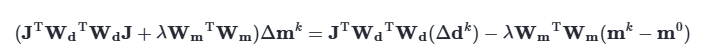

This allows us to find delta-m which indicates the direction of the model update. **But it should be noted that a transformation by scalar tau is needed to determine the actual step increase.** This is found in PyGIMLi by doing a line search.

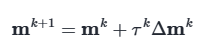



In [14]:
#Determine what type of variable to invert for

invert_for = 'complex' #options 'real', 'amp', 'comp'

def convert(data):
    
    if invert_for == 'real':
        data_out = np.real(data)
    elif invert_for == 'amplitude':
        data_out = np.abs(data)
    elif invert_for == 'complex':
        data_out = data
    return data_out


In [15]:
%%time

def input_map(x, inp=inp):
    """Map the inversion parameter to modelling parameters."""
    # Could be res, aniso, depth, a mixture of it, ...
    inp['res'] =  np.r_[2e14, x, base_res]
    return inp


def output_map(em):
    #em_out = np.r_[convert(em.ravel())]
    em_out = np.r_[convert(em).ravel().real, convert(em).ravel().imag if np.iscomplexobj(convert(em)) else []]
    return em_out

#print(output_map(np.array([1])))

fop = Kernel(input_map, output_map, empymod.bipole)
inv = Inversion(fop=fop)

# Not Sure Yet How To Use These (comment from Dieter)
#inv.dataTrans = pygimli.trans.TransSymLog(1e-20)
#inv.transModel = pygimli.trans.TransLog(0.1) # > 1 Ohmm

#inv.modelTrans = 'log'


minv_list = []
chi2_list = []
it_amount = []
phi_list = []
for i in np.arange(len(dobs_list)):

    out, response = inv.run(
        dataVals=convert(dobs_list[i]),
        absoluteError=convert(std_dev_list[i]),
        #relativeError=0.01,
        startModel=m0[1:-1],
        verbose = False,
        dPhi=2, #Sets percentage change of objective function at which the inversion should stop
        #max_iter = 30,
        lam=500#lam
    )

    # Get inversion result from parameter dict
    # Could be res, aniso, depth, ...
    minv = out['res']
    minv_list.append(minv)
    chi2_list.append(inv.chi2History[-1])
    it_amount.append(len(inv.chi2History))
    phi_list.append(inv.phi(response=fop.response(minv[1:-1])))



















































































CPU times: total: 11min 13s
Wall time: 11min 32s


## Compute the DGSA

the package pyDGSA is not compatible with PyGIMLi because it relies on a higher version of numpy. Therefore the data is exported and DGSA is computed in a different script

In [103]:
#Save inversion information as response for sensitivity analysis

# recall: params_list.append([anom_res, thick, depth, relative_error, i])

parameters = np.array(params_list[::5])[:,:4]
#print(np.shape(params_list))
#print(np.shape(parameters))

responses = np.empty((parameters.shape[0], 5), dtype="float64")
responses[:,0] = np.average(np.array(phi_list).reshape(-1,16), axis=0) #Average remanent misfit phi
responses[:,1] = np.average(np.array(chi2_list).reshape(-1,16), axis=0) #Average final chi2 value
responses[:,2] = np.average(np.array(it_amount).reshape(-1,16), axis=0) #Average amount of iterations

for i in np.arange(parameters.shape[0]):
    mtrue = mtrue_list[i]
    anom_depth = parameters[i][2]
    anom_thick = parameters[i][1]
    anom_res = parameters[i][0]

    anom_errs = []
    for j in np.arange(5):
        minv = minv_list[i*5+j]
        anom_errs.append(np.mean(minv[1+int(anom_depth/10):1+int((anom_depth+anom_thick)/10)])-anom_res)

    responses[i,3] = np.mean(anom_errs) #Anomaly error (absolute)
    responses[i,4] = responses[i,4]/anom_res #Anomaly error (relative)

In [104]:
import numpy as np

In [106]:
#Save information in order to compute DGSA

np.savetxt("20260727_empymod_pyGIMLi_DGSA_test_v1_parameters.txt", parameters)
np.savetxt("20260727_empymod_pyGIMLi_DGSA_test_v1_responses.txt", responses)

all_sim_info = np.zeros((parameters.shape[0], parameters.shape[1]+responses.shape[1]))
all_sim_info[:,:parameters.shape[1]] = parameters
all_sim_info[:,parameters.shape[1]:] = responses
table = pd.DataFrame(all_sim_info, columns = ["anom_res", "anom_thickn", "anom_depth", "rel_noise", 'Phi', 'Chi2', 'Iterations', 'Abs. deviation', 'Rel. deviation'])
table = table.sort_values(by=["Rel. deviation"])
display(table)

,anom_res,anom_thickn,anom_depth,rel_noise,Phi,Chi2,Iterations,Abs. deviation,Rel. deviation
0,13.0,10.0,150.0,0.01,1761.955517,1.078017,4.6,0.096554,0.0
1,13.0,10.0,150.0,0.20,9909.385061,1.140119,4.6,6.743557,0.0
2,13.0,10.0,210.0,0.01,3701.510093,1.144945,4.8,0.186442,0.0
3,13.0,10.0,210.0,0.20,1721.706731,1.143785,4.2,8.525366,0.0
4,13.0,80.0,150.0,0.01,3896.072539,1.039403,5.2,0.016134,0.0
5,13.0,80.0,150.0,0.20,918.869508,1.243552,5.4,0.994170,0.0
6,13.0,80.0,210.0,0.01,6957.312342,1.054070,5.0,0.004322,0.0
7,13.0,80.0,210.0,0.20,838.067831,1.215052,5.0,0.570538,0.0
8,25.0,10.0,150.0,0.01,7250.696808,1.093576,4.8,0.029205,0.0
9,25.0,10.0,150.0,0.20,931.645204,1.124794,3.8,5.062792,0.0


## Plot results

16


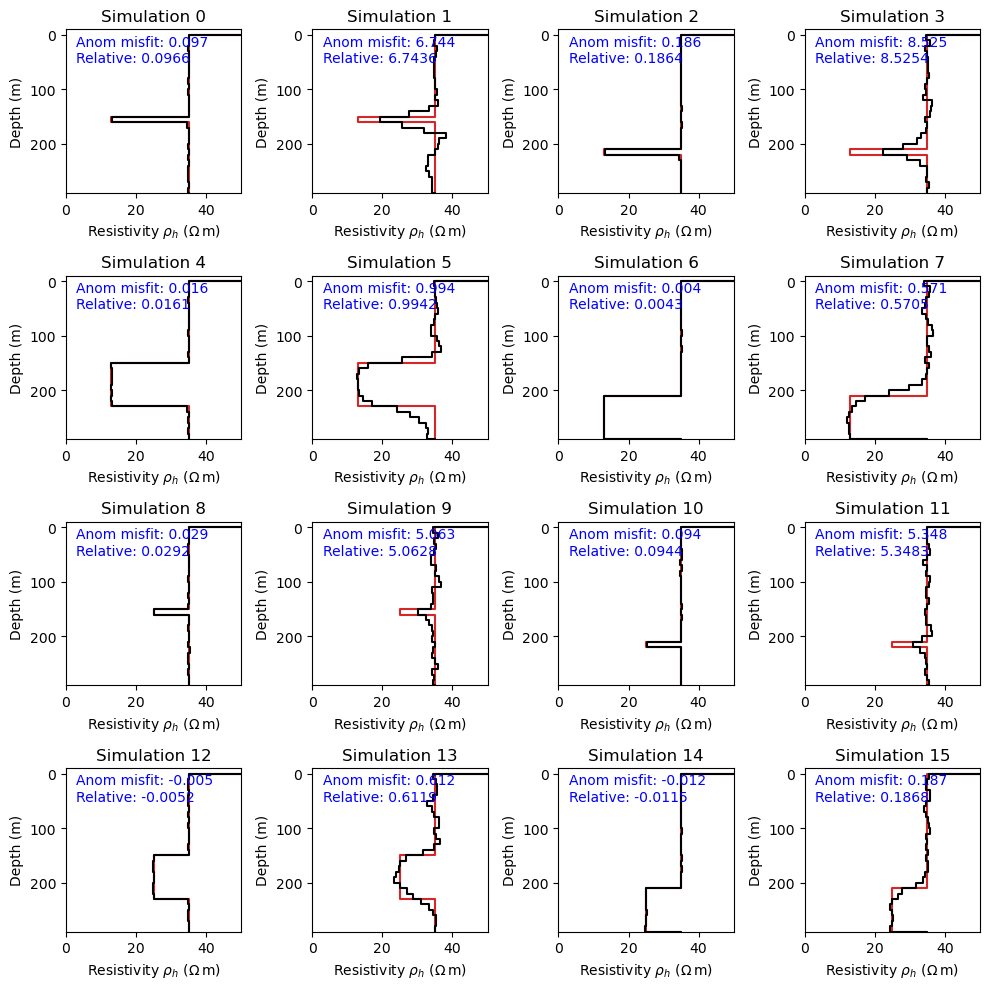

In [ ]:
#We plot results for all the parameter choices

# Plot it
fig, axs = plt.subplots(4, int(parameters.shape[0]/4+0.5), figsize=(10, 10), tight_layout=True)

p_depth = np.r_[-10, np.repeat(depths, 2), 3000]
p_m0 = np.repeat(m0, 2)
print(parameters.shape[0])
for i in np.arange(parameters.shape[0]):
    p_mtrue = np.repeat(mtrue_list[::5][i], 2)
    p_minv = np.repeat(minv_list[::5][i], 2)

    ax1=axs[int(i/4), i%4]

    # Plot Resistivities
    ax1.set_title('Simulation '+str(i))
    ax1.plot(p_mtrue, p_depth, 'C3', label="True Model")
    ax1.plot(p_minv, p_depth, 'k', label="Inversion Model")
    ax1.annotate('Anom misfit: '+str(np.round(responses[i, 3],3)), (3, 20), color = 'blue')
    ax1.annotate('Relative: '+str(np.round(responses[i, 3],4)), (3, 50), color = 'blue')
    #ax1.set_xscale('log')
    ax1.set_xlim([0, 50])
    ax1.set_ylim([depths[-1], depths[0]-10])
    ax1.set_ylabel('Depth (m)')
    ax1.set_xlabel(r'Resistivity $\rho_h\ (\Omega\,\rm{m})$')

    #ax1.legend(loc='lower center')#, bbox_to_anchor = (0.5,-0.25))

In [8]:
empymod.Report(['pyGIMLi', 'pgcore'])

--------------------------------------------------------------------------------
  Date: Mon Jun 01 11:50:33 2026 UTC

                OS : Windows (10 10.0.26100 SP0 Multiprocessor Free)
            CPU(s) : 14
           Machine : AMD64
      Architecture : 64bit
               RAM : 31.4 GiB
       Environment : Jupyter

  Python 3.11.15 | packaged by conda-forge | (main, Mar  5 2026, 16:36:00)
  [MSC v.1944 64 bit (AMD64)]

           pyGIMLi : 1.5.5
            pgcore : 1.5.0
             numpy : 1.26.4
             scipy : 1.14.1
             numba : 0.65.1
           empymod : 2.5.4
            libdlf : 0.3.0
           IPython : 9.10.0
        matplotlib : 3.10.9
--------------------------------------------------------------------------------